In [24]:
# Steel Industry Energy Consumption
# The data is collected from a smart small-scale steel industry in South Korea.
# https://archive.ics.uci.edu/dataset/198/steel%2B

In [23]:
# Primeiros passos:

# Importar biblioteca
import pandas as pd

# Carregar dataset
df = pd.read_csv("Steel_industry_data.csv", sep=",")

# Mostrar
print("Shape:",df.shape)
print(display(df.head())) # print-display é pra facilitar a cópia das saídas no VSCode

Shape: (35040, 11)


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


None


Descrição das features

| Variável                               | Descrição                                      |
| -------------------------------------- | ---------------------------------------------- |
| `date`                                 | Data e horário da medição                      |
| `Usage_kWh`                            | Consumo de energia                             |
| `Lagging_Current_Reactive.Power_kVarh` | Potência reativa indutiva                      |
| `Leading_Current_Reactive_Power_kVarh` | Potência reativa capacitiva                    |
| `CO2(tCO2)`                            | Emissão de CO₂                                 |
| `Lagging_Current_Power_Factor`         | Fator de potência indutivo                     |
| `Leading_Current_Power_Factor`         | Fator de potência capacitivo                   |
| `NSM`                                  | Segundos após meia-noite                       |
| `WeekStatus`                           | Dia útil ou fim de semana                      |
| `Day_of_week`                          | Dia da semana                                  |
| `Load_Type`                            | Classificação da carga (leve, média ou máxima) |

### O que estamos tentando prever?
A variável-alvo Load_Type identifica o tipo de carga industrial a partir das demais variáveis.

In [2]:
# Primeira inspeção dos dados

print("----------------------------------------------------------------------------------------------------------------------------")
print("Info:\n")
df.info()

print("----------------------------------------------------------------------------------------------------------------------------")
print("Describe:\n")
display(df.describe(include="all").T)

print("----------------------------------------------------------------------------------------------------------------------------")
print("Valores ausentes:\n")
print(df.isna().sum())

print("----------------------------------------------------------------------------------------------------------------------------")
print("Distribuição da variável-alvo:\n")
print(df["Load_Type"].value_counts(normalize=True) * 100)

----------------------------------------------------------------------------------------------------------------------------
Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,35040,35040,01/01/2018 00:15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Usage_kWh,35040.0,NaN,NaN,NaN,27.386892,33.44438,0.0,3.2,4.57,51.2375,157.18
Lagging_Current_Reactive.Power_kVarh,35040.0,NaN,NaN,NaN,13.035384,16.306,0.0,2.3,5.0,22.64,96.91
Leading_Current_Reactive_Power_kVarh,35040.0,NaN,NaN,NaN,3.870949,7.424463,0.0,0.0,0.0,2.09,27.76
CO2(tCO2),35040.0,NaN,NaN,NaN,0.011524,0.016151,0.0,0.0,0.0,0.02,0.07
Lagging_Current_Power_Factor,35040.0,NaN,NaN,NaN,80.578056,18.921322,0.0,63.32,87.96,99.0225,100.0
Leading_Current_Power_Factor,35040.0,NaN,NaN,NaN,84.36787,30.456535,0.0,99.7,100.0,100.0,100.0
NSM,35040.0,NaN,NaN,NaN,42750.0,24940.534317,0.0,21375.0,42750.0,64125.0,85500.0
WeekStatus,35040,2,Weekday,25056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_week,35040,7,Monday,5088,NaN,NaN,NaN,NaN,NaN,NaN,NaN


----------------------------------------------------------------------------------------------------------------------------
Valores ausentes:

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64
----------------------------------------------------------------------------------------------------------------------------
Distribuição da variável-alvo:

Light_Load      51.575342
Medium_Load     27.671233
Maximum_Load    20.753425
Name: Load_Type, dtype: float64


### Observações:

Variável date:
Está armazenada como object, então precisaremos convertê-la para datetime para extrair informações temporais.

Usage_kWh:
A média muito superior à mediana sugere uma distribuição assimétrica à direita. Provavelmente existem diferenças expressivas entre os períodos de baixa e alta carga.

Load_Type:
Temos uma distribuição de classes razoavelmente desequilibrada, mas nada extremamente preocupante.
A classe majoritária representa aproximadamente 51,6% dos registros, enquanto a minoritária representa 20,8%.

In [22]:
# Vamos começar a análise com as duas tabelas de contingência, mostrando as quantidades 
# e as porcentagens de cada classe dentro de cada categoria.

# Distribuição de Load_Type por WeekStatus

ctab_absoluta_loadT_Wstatus = pd.crosstab(
    df['WeekStatus'],
    df['Load_Type'],
    margins=True # Total
)

print("Distribuição de Load_Type por WeekStatus")
display(ctab_absoluta_loadT_Wstatus)
print("----------------------------------------------------------------")

# Distribuição percentual de Load_Type por WeekStatus

ctab_percentual_loadT_Wstatus = pd.crosstab(
    df['WeekStatus'],
    df['Load_Type'],
    normalize='index',
).mul(100).round(2) # Normalizar e multiplicar por 100 depois, pra interpretar como porcentagem

print("Distribuição percentual de Load_Type por WeekStatus")
display(ctab_percentual_loadT_Wstatus)
print("----------------------------------------------------------------")

# Distribuição de Load_Type por Day_of_week

ctab_absoluta_loadT_DayOW = pd.crosstab(
    df['Day_of_week'],
    df['Load_Type'],
    margins=True
)

print("Distribuição de Load_Type por Day_of_week")
display(ctab_absoluta_loadT_DayOW)
print("----------------------------------------------------------------")

# Distribuição percentual de Load_Type por Day_of_week

ctab_percentual_loadT_DayOW = pd.crosstab(
    df['Day_of_week'],
    df['Load_Type'],
    normalize='index' # Normalizar e multiplicar por 100 depois, pra interpretar como porcentagem
).mul(100).round(2)

print("Distribuição percentual de Load_Type por Day_of_week")
display(ctab_percentual_loadT_DayOW)

Distribuição de Load_Type por WeekStatus


Load_Type,Light_Load,Maximum_Load,Medium_Load,All
WeekStatus,,,,
Weekday,11168,5952,7936,25056
Weekend,6904,1320,1760,9984
All,18072,7272,9696,35040


----------------------------------------------------------------
Distribuição percentual de Load_Type por WeekStatus


Load_Type,Light_Load,Maximum_Load,Medium_Load
WeekStatus,,,
Weekday,44.57,23.75,31.67
Weekend,69.15,13.22,17.63


----------------------------------------------------------------
Distribuição de Load_Type por Day_of_week


Load_Type,Light_Load,Maximum_Load,Medium_Load,All
Day_of_week,,,,
Friday,2192,1200,1600,4992
Monday,2288,1200,1600,5088
Saturday,2864,912,1216,4992
Sunday,4040,408,544,4992
Thursday,2192,1200,1600,4992
Tuesday,2248,1176,1568,4992
Wednesday,2248,1176,1568,4992
All,18072,7272,9696,35040


----------------------------------------------------------------
Distribuição percentual de Load_Type por Day_of_week


Load_Type,Light_Load,Maximum_Load,Medium_Load
Day_of_week,,,
Friday,43.91,24.04,32.05
Monday,44.97,23.58,31.45
Saturday,57.37,18.27,24.36
Sunday,80.93,8.17,10.90
Thursday,43.91,24.04,32.05
Tuesday,45.03,23.56,31.41
Wednesday,45.03,23.56,31.41


WeekStatus:
- Nos finais de semana, há uma concentração muito maior de registros classificados como Light_Load.

Day_of_week:
- No domingo, 80,93% dos registros são Light_Load.
- O sábado também apresenta uma proporção maior de cargas leves (57,37%), embora menos acentuada.
- Já de segunda a sexta, as distribuições são bastante semelhantes, com aproximadamente 44–45% de cargas leves, 23–24% de cargas máximas e 31–32% de cargas médias.

Repare também que os números absolutos são bastante equilibrados entre os dias da semana (aproximadamente 5 mil registros por dia). Portanto, as diferenças percentuais não parecem decorrer simplesmente de uma quantidade muito maior de observações em determinado dia.

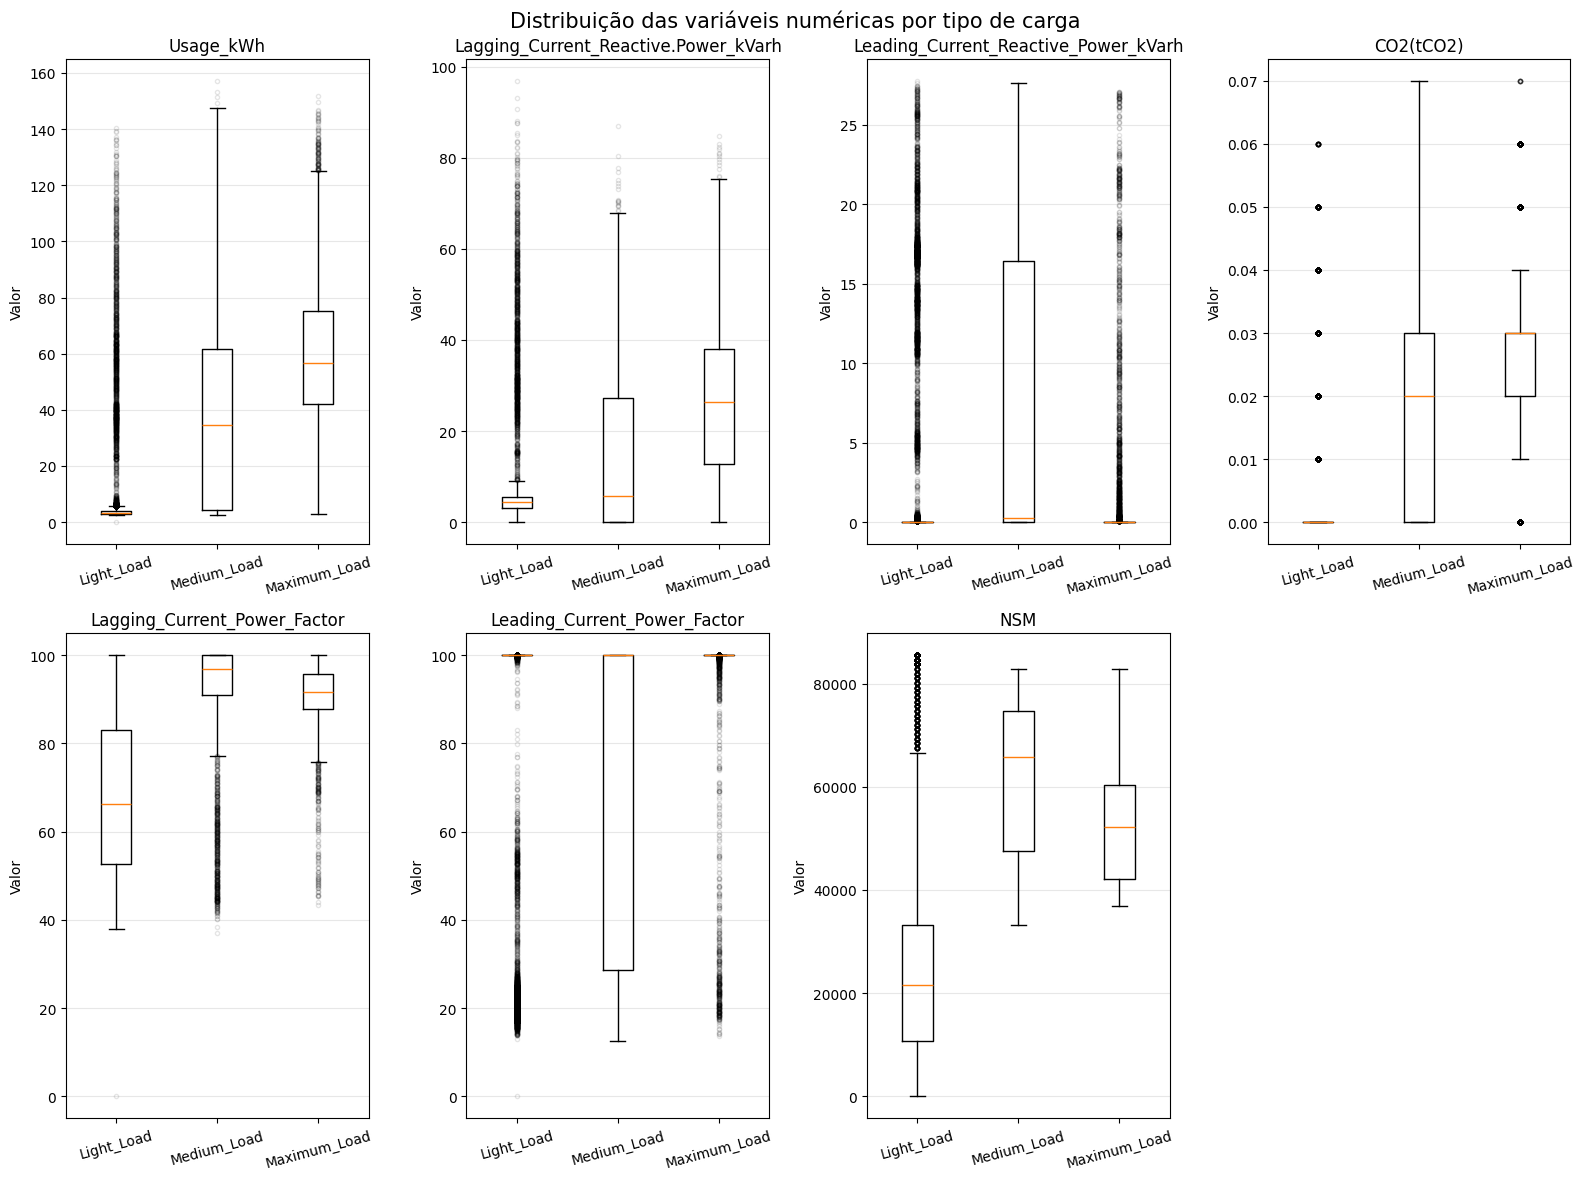

In [28]:

# Agora vamos usar boxplots para comparar as distribuições das variáveis numéricas
# entre as três classes da variável-alvo. Eles permitem comparar medianas,
# dispersões e valores extremos.

import matplotlib.pyplot as plt

# Variáveis numéricas que serão comparadas.
numeric_cols = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM"
]

# Classes da variável-alvo.
classes = ["Light_Load", "Medium_Load", "Maximum_Load"]

# Criar uma grade de gráficos com 3 linhas e 3 colunas.
fig, axes = plt.subplots(2, 4, figsize=(16, 12))

# Comparar a distribuição de cada variável entre as classes.
for col, ax in zip(numeric_cols, axes.flatten()):

    # Separar os valores de acordo com o tipo de carga.
    data = [
        df.loc[df["Load_Type"] == classe, col]
        for classe in classes
    ]

    # Construir o boxplot.
    ax.boxplot(
        data,
        labels=classes,
        showfliers=True,
        flierprops=dict(
            marker="o",
            markersize=3,
            alpha=0.1
        )
    )

    ax.set_title(col)
    ax.set_ylabel("Valor")
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", labelrotation=15)

# Remover os dois espaços não utilizados na grade.
for ax in axes.flatten()[len(numeric_cols):]:
    ax.remove()

# Ajustar o espaçamento entre os gráficos.
plt.suptitle(
    "Distribuição das variáveis numéricas por tipo de carga",
    fontsize=15
)

plt.tight_layout()
plt.show()


Análise dos Boxplots

As diferenças entre os tipos de carga são mais evidentes em `Usage_kWh`, `NSM` e `CO2(tCO2)`, que apresentam medianas distintas entre os grupos. Em `Lagging_Current_Reactive.Power_kVarh`, a carga máxima também apresenta valores centrais mais elevados, enquanto as cargas leve e média possuem maior proximidade.

Em `Lagging_Current_Power_Factor`, as cargas médias e máximas apresentam concentrações em valores elevados, enquanto as leves possuem maior dispersão. Já em `Leading_Current_Power_Factor`, destaca-se a distribuição bastante espalhada da carga média, em contraste com as caixas estreitas das cargas leve e máxima, concentradas próximas de 100.

De modo geral, a dispersão e a presença de outliers em diversas variáveis indicam que existe heterogeneidade dentro dos próprios grupos, além de possíveis sobreposições entre os tipos de carga.

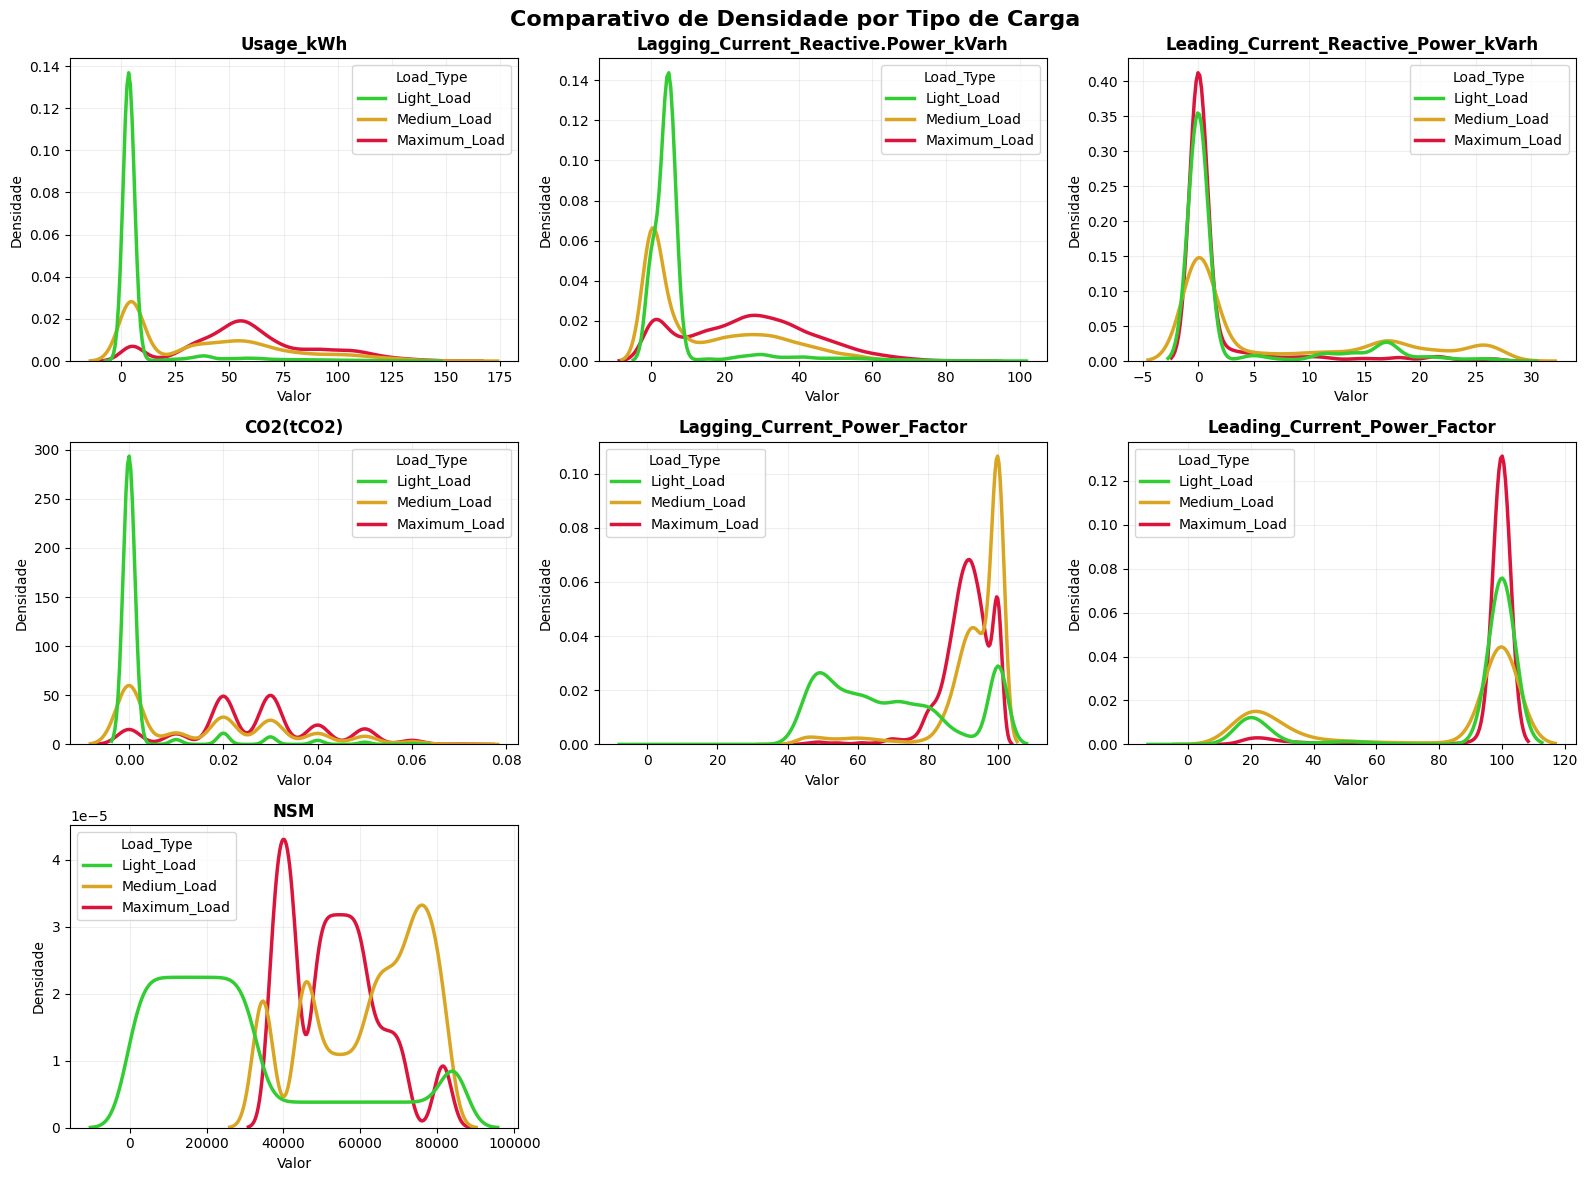

In [39]:
# Agora vamos utilizar curvas KDE para investigar a distribuição das variáveis numéricas
# e identificar concentrações de valores, assimetrias e possíveis padrões.

import matplotlib.pyplot as plt
import seaborn as sns

# Variáveis numéricas
numeric_cols = [
    "Usage_kWh",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "CO2(tCO2)",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM"
]

# Criar a grade 3x3
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

cores = ["limegreen", "goldenrod", "crimson"]
# Outras opções:
# cores_impacto = ["#007edb", "#ff9900", "#e6194B"] 
# Light = Azul Vivo, Medium = Laranja/Amarelo Alerta, Maximum = Vermelho/Rosa Choque


for i, col in enumerate(numeric_cols):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Load_Type",
        fill=False, # True = pinta a área abaixo da curva   
        linewidth=2.5, # grossura da linha
        palette=cores,
        common_norm=False,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Densidade")
    axes[i].grid(axis="both", alpha=0.2)

# Remove os eixos vazios que sobram na grade 3x3
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Comparativo de Densidade por Tipo de Carga", 
    fontsize=16, 
    fontweight='bold', 
    y=0.98
)
plt.tight_layout()
plt.show()


Análise das Curvas KDE

As curvas KDE revelam um padrão interessante: em diversas variáveis, a predominância entre os tipos de carga muda conforme a região da distribuição. Em `Usage_kWh`, `Lagging_Current_Reactive.Power_kVarh` e `CO2(tCO2)`, por exemplo, as cargas leves predominam nas primeiras regiões de concentração, enquanto as máximas ganham destaque em regiões posteriores, com as médias geralmente ocupando uma posição intermediária.

Esse comportamento também aparece em `Leading_Current_Power_Factor` e `Leading_Current_Reactive_Power_kVarh`, embora com uma inversão diferente na ordem de predominância entre as classes. Já `NSM` apresenta uma alternância particularmente evidente, com regiões em que predominam, sucessivamente, as cargas leves, máximas e médias. Algo semelhante ocorre em `Lagging_Current_Power_Factor`.

Esses padrões sugerem que diferentes faixas de valores podem fornecer informações complementares para distinguir os tipos de carga. Entretanto, a sobreposição entre as curvas indica que essas características dificilmente serão suficientes quando consideradas isoladamente.

In [ ]:
# A continuação será lançada em breve...